# Metal supply projections — method comparison

Every available projection method for each study metal, side by side, from
`build/supply/all_supply.nc` (see `scripts/supply_helpers.py` for the schema). All
values are market-ready supply in **kt/yr**.

| method | meaning |
|---|---|
| `direct` | final-stage series (refinery / smelter-for-Al / OWID "processing") used as-is |
| `mine_recovery` | mine-stage series × smelting+refining recovery rate (Nassar et al. 2022, Table S4) |
| `host_ratio` | host mine series × extrapolated by-product ratio |
| `source_projection` | the source's own model (Lundaev bell curve) |

Sources: `owid` (USGS/BGS history, linearly extrapolated over the config
window), `iea` (Global Critical Minerals Outlook 2026 base case, interpolated,
2040 held to 2050),
`lundaev` (Lundaev et al. 2023 history + bell curves).

Run by the `visualise_supplies` snakemake rule, or interactively (paths then
resolve relative to the repo root).

In [1]:
import sys
from pathlib import Path

import matplotlib.lines as mlines
import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr
import yaml

# Snakemake runs this from the repo root, an interactive session from
# notebooks/; neither puts scripts/ on the path, so do it by hand.
repo = Path.cwd() if (Path.cwd() / "snakefile").exists() else Path.cwd().parent
sys.path.insert(0, str(repo / "scripts"))

import plotting  # noqa: E402 — needs the path above
import supply_helpers  # noqa: E402
from info_schemas import MineralGroup, MineralInfo  # noqa: E402

try:
    paths = {
        "supply": snakemake.input.supply,  # noqa: F821 — injected by the snakemake notebook rule
        "owid": snakemake.input.owid,  # noqa: F821
        "iea": snakemake.input.iea,  # noqa: F821
        "lundaev": snakemake.input.lundaev,  # noqa: F821
        "ratios": snakemake.input.ratios,  # noqa: F821
        "mineral_info": snakemake.input.mineral_info,  # noqa: F821
        "figures": snakemake.output.figures,  # noqa: F821
    }
    style = dict(snakemake.params.plotting)  # noqa: F821
except NameError:  # interactive run
    with open(repo / "config/default.yaml") as f:
        style = yaml.safe_load(f)["plotting"]
    paths = {
        "supply": repo / "build/supply/all_supply.nc",
        "owid": repo / "build/supply/minerals_owid.nc",
        "iea": repo / "build/supply/minerals_iea.nc",
        "lundaev": repo / "build/supply/minerals_lundaev.nc",
        "ratios": repo / "build/supply/byproduct_ratios.csv",
        "mineral_info": repo / "data/mineral_info.csv",
        "figures": repo / "build/supply/figures",
    }

figures_dir = Path(paths["figures"])
figures_dir.mkdir(parents=True, exist_ok=True)
plotting.apply_style(style)
ink = style["ink"]

In [2]:
supply = xr.load_dataset(paths["supply"])
datasets = {s: xr.load_dataset(paths[s]) for s in ("owid", "iea", "lundaev")}
ratios = pd.read_csv(paths["ratios"])
mineral_info = pd.read_csv(paths["mineral_info"])
supply

<xarray.Dataset> Size: 146kB
Dimensions:       (source: 3, mineral: 25, method: 4, year: 51)
Coordinates:
  * source        (source) <U7 84B 'owid' 'iea' 'lundaev'
  * mineral       (mineral) <U19 2kB 'Aluminium' ... 'Rare earth elements'
  * method        (method) <U17 272B 'direct' ... 'source_projection'
  * year          (year) int64 408B 2000 2001 2002 2003 ... 2047 2048 2049 2050
Data variables:
    supply        (source, mineral, method, year) float64 122kB 2.43e+04 ... nan
    projected     (source, mineral, method, year) bool 15kB False ... False
    direct_stage  (source, mineral) <U10 3kB 'smelter' 'refinery' ... '' ''
    total_supply  (source, mineral, method) float64 2kB 2.681e+06 nan ... nan

In [3]:
SOURCE_COLORS = {"owid": "#2a78d6", "iea": "#1baf7a", "lundaev": "#eda100"}
METHOD_STYLES = {
    "direct": "-",
    "mine_recovery": "--",
    "host_ratio": "-.",
    "source_projection": ":",
}
# Bar-chart counterpart of METHOD_STYLES, so a method reads the same in the
# yearly line plots and the window-total bars.
METHOD_HATCHES = {
    "direct": "",
    "mine_recovery": "//",
    "host_ratio": "..",
    "source_projection": "xx",
}
# The same filter the extrapolate_* rules used to build the cube, so the panels
# cannot drift from what was projected.
SUPPLY_MINERALS = list(supply_helpers.supply_minerals(mineral_info)[MineralInfo.mineral])

## What is available where

One `x` per (mineral, source, method) with any data.

In [4]:
availability = (
    supply["supply"]
    .notnull()
    .any("year")
    .to_dataframe("available")["available"]
    .unstack(["source", "method"])
    .reindex(SUPPLY_MINERALS)
)
availability = availability.loc[:, availability.any()]
availability.replace({True: "x", False: ""})

source                owid                             iea                \
method              direct mine_recovery host_ratio direct mine_recovery   
mineral                                                                    
Aluminium                x                                                 
Cadmium                  x                                                 
Cobalt                   x             x                 x             x   
Copper                   x             x                 x             x   
Dysprosium                                                                 
Gallium                  x                        x                        
Germanium                x                        x                        
Graphite                               x                 x             x   
Indium                                                                     
Iridium                                           x                        
Lithium                                x                 x             x   
Manganese                              x                                   
Molybdenum                             x                                   
Neodymium                                                                  
Nickel                   x             x                 x             x   
Niobium                                x                                   
Platinum                               x                                   
Praseodymium                                                               
Selenium                 x                                                 
Silver                                 x                                   
Tellurium                                                                  
Terbium                                                                    
Tin                                    x                                   
Vanadium                               x                                   
Rare earth elements                    x                 x             x   

source              lundaev                                             
method               direct mine_recovery host_ratio source_projection  
mineral                                                                 
Aluminium                 x                                          x  
Cadmium                   x                                          x  
Cobalt                                  x                            x  
Copper                                  x                            x  
Dysprosium                              x                            x  
Gallium                   x                                          x  
Germanium                 x                        x                 x  
Graphite                                                                
Indium                    x                                          x  
Iridium                                 x          x                 x  
Lithium                                 x                            x  
Manganese                               x                            x  
Molybdenum                              x                            x  
Neodymium                               x                            x  
Nickel                                  x                            x  
Niobium                                                                 
Platinum                                x                            x  
Praseodymium                            x                            x  
Selenium                  x                                          x  
Silver                                  x                            x  
Tellurium                 x                                          x  
Terbium                                 x                            x  
Tin                                           

## Per-metal comparison

One cell per metal, two cells to a row, over as many pages as that takes.

Within a cell: colour = source, linestyle = method. Faint = observed history (as
the method sees it, i.e. already converted to market-ready supply); strong =
projected. The shaded band marks the integration window. The bars beside them
are `total_supply`: each yearly series summed over that window (kt) — matching
hatch = matching method.

The bars are named only by the figure's key: at a sixth of the page a name like
`lundaev · source_projection` is wider than the panel it belongs to. The marker
points at the series `data/mineral_info.csv` picks.


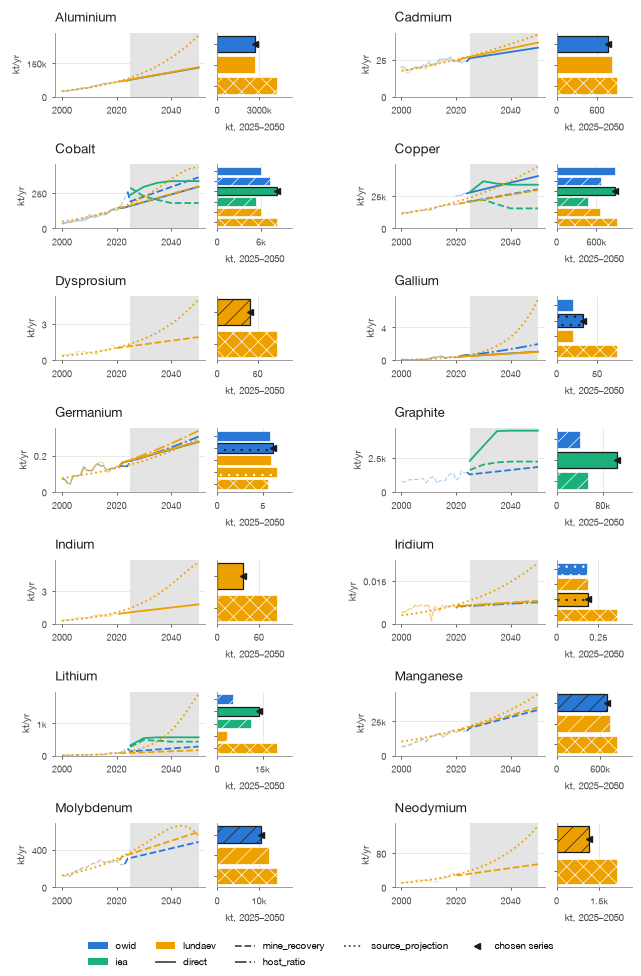

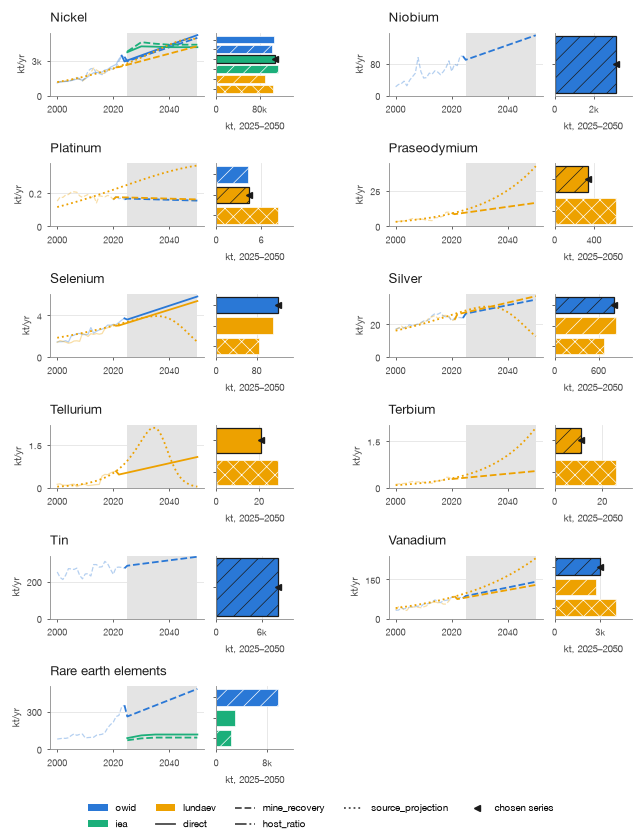

In [5]:
WINDOW = (int(supply["year"].min()), int(supply["year"].max()))
if "total_supply" in supply:
    # total_supply carries the exact integration window in its attrs
    import re
    span = re.search(r"(\d{4})-(\d{4})", supply["total_supply"].attrs.get("description", ""))
    if span:
        WINDOW = (int(span.group(1)), int(span.group(2)))

# The (source, method) picked per metal in mineral_info.csv, for the bar plot to
# flag. Blank for non-targets (the REE aggregate row).
mineral_choices = mineral_info.set_index(MineralInfo.mineral)

# A cell is one metal: its yearly series, and beside them the same series
# integrated over the window. Two cells to a row.
CELL_RATIOS = [2.0, 1.0]
CELLS_PER_ROW = 2
# How the one series mineral_info.csv picks is flagged, on the bar and in the key.
CHOSEN_MARKER = dict(marker="<", markersize=4, linestyle="none")


def plot_mineral(mineral, ax):
    """The yearly series of one metal, one line per (source, method)."""
    for source in map(str, supply["source"].values):
        for method in map(str, supply["method"].values):
            selection = dict(source=source, mineral=mineral, method=method)
            series = supply["supply"].sel(selection).to_pandas()
            if series.isna().all():
                continue
            projected = supply["projected"].sel(selection).to_pandas()
            observed = series.where(~projected)
            projection = series.where(projected)
            last_observed = observed.last_valid_index()
            if last_observed is not None and projection.notna().any():
                projection.loc[last_observed] = observed.loc[last_observed]
            color = SOURCE_COLORS[source]
            line_style = METHOD_STYLES[method]
            ax.plot(observed.index, observed, line_style, color=color, alpha=0.35,
                    lw=0.9)
            ax.plot(projection.index, projection, line_style, color=color, lw=1.3)
    ax.axvspan(*WINDOW, color=ink["grid"], lw=0, zorder=0)
    ax.set_ylim(bottom=0)
    plotting.style_panel(ax, style, title=mineral, ylabel="kt/yr")
    plotting.compact_ticks(ax, style, "metal_panel", "vertical")


def plot_totals(mineral, ax):
    """Window-integrated supply (total_supply) as one bar per source · method.

    The bars are named only by the figure's legend — at a sixth of the page a
    name like "lundaev · source_projection" is wider than the panel — and the
    one mineral_info.csv picks is outlined and marked.
    """
    values, colors, hatches, combos = [], [], [], []
    for source in map(str, supply["source"].values):
        for method in map(str, supply["method"].values):
            total = supply["total_supply"].sel(
                dict(source=source, mineral=mineral, method=method)
            ).item()
            if pd.isna(total):
                continue
            values.append(total)
            colors.append(SOURCE_COLORS[source])
            hatches.append(METHOD_HATCHES[method])
            combos.append((source, method))
    positions = list(range(len(values)))
    bars = ax.barh(
        positions, values, color=colors,
        edgecolor=style["bar"]["edge_color"], linewidth=style["bar"]["edge_width"],
    )
    for bar, hatch in zip(bars, hatches):
        bar.set_hatch(hatch)
    ax.set_yticks(positions, [""] * len(positions))
    ax.invert_yaxis()
    ax.set_xlim(0, max(values) * 1.25)  # headroom for the "chosen" tick
    plotting.style_panel(
        ax, style, title=None, orientation="horizontal",
        ylabel=f"kt, {WINDOW[0]}–{WINDOW[1]}",
    )
    plotting.compact_ticks(ax, style, "metal_panel", "horizontal")

    # Flag the source · method picked in mineral_info.csv. Blank for the REE
    # aggregate row (not a supply target); a pick that isn't an available bar is
    # a mismatch between the CSV and the data, so raise rather than pass silently.
    choice = mineral_choices.loc[mineral]
    source = choice[supply_helpers.CHOSEN_SOURCE_COL]
    method = choice[supply_helpers.CHOSEN_METHOD_COL]
    if pd.isna(source) and pd.isna(method):
        return
    if (source, method) not in combos:
        raise ValueError(
            f"{mineral}: chosen {source} · {method} is not an available bar"
        )
    chosen = combos.index((source, method))
    bars[chosen].set_edgecolor(ink["primary"])
    bars[chosen].set_linewidth(0.9)
    # A marker rather than a tick character: the study's font has no glyph for
    # one, and a missing glyph prints as a box.
    ax.plot(
        values[chosen], positions[chosen], color=ink["primary"],
        clip_on=False, zorder=3, **CHOSEN_MARKER,
    )


def supply_legend(fig):
    """Colour is the source, dash the method on the lines and hatch the same
    method on the bars; the marker is the series mineral_info.csv picks."""
    return fig.legend(
        handles=[
            *plotting.patch_handles(
                SOURCE_COLORS, SOURCE_COLORS, {s: s for s in SOURCE_COLORS}
            ),
            *[
                mlines.Line2D(
                    [], [], color=ink["secondary"], linestyle=METHOD_STYLES[method],
                    linewidth=1.3, label=method,
                )
                for method in METHOD_STYLES
            ],
            mlines.Line2D(
                [], [], color=ink["primary"], label="Chosen series", **CHOSEN_MARKER
            ),
        ],
        # Two rows rather than one: eight entries across the page would set the
        # figure's width, and the width is the page's to set.
        loc="outside lower center", frameon=False, ncol=5,
    )


for page, (fig, cells, page_minerals) in enumerate(
    plotting.paged_cell_grid(SUPPLY_MINERALS, style, CELL_RATIOS, CELLS_PER_ROW),
    start=1,
):
    for (ax_yearly, ax_total), mineral in zip(cells, page_minerals):
        plot_mineral(mineral, ax_yearly)
        plot_totals(mineral, ax_total)
    # No title over the figure: the caption is written where it is published,
    # and which page of the set this is, is in its file name.
    legend = supply_legend(fig)
    plotting.save_figure(
        fig, figures_dir, f"supply_per_metal_{page}", style, (legend,)
    )
    plt.show()


## By-product ratios

The `host_ratio` method multiplies the extrapolated host mine series by these
ratios (`build/supply/byproduct_ratios.csv`). Gallium's ratio trends upward
(recovery buildout), which is why the ratio itself is extrapolated rather than
held constant.

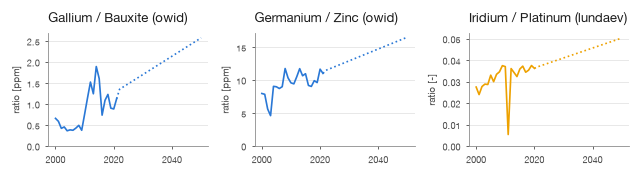

In [6]:
year_cols = [c for c in ratios.columns if c.isdigit()]
fig, axes = plotting.page_grid(len(ratios), style)
for ax, (_, row) in zip(axes, ratios.iterrows()):
    series = row[year_cols].astype(float)
    series.index = series.index.astype(int)
    in_ppm = series.max() < 1e-3
    scale = 1e6 if in_ppm else 1.0
    color = SOURCE_COLORS[row["source"]]
    observed = series[series.index <= row["last_observed_year"]] * scale
    future = series[series.index >= row["last_observed_year"]] * scale
    ax.plot(observed.index, observed, color=color)
    ax.plot(future.index, future, ":", color=color)
    ax.set_ylim(bottom=0)
    plotting.style_panel(
        ax,
        style,
        title=f"{row['byproduct']} / {row['host']} ({row['source']})",
        ylabel="Ratio [ppm]" if in_ppm else "Ratio [-]",
    )
plotting.save_figure(fig, figures_dir, "byproduct_ratios", style)
plt.show()

## REE sanity check

The Lundaev co-product projections (Nd + Pr + Dy summed) should sit near the
IEA *magnet* REE aggregate (same scope, minus Tb) and safely **below** the
OWID total-REO aggregate (much wider scope) — see the scope notes in
`data/mineral_info.csv`.

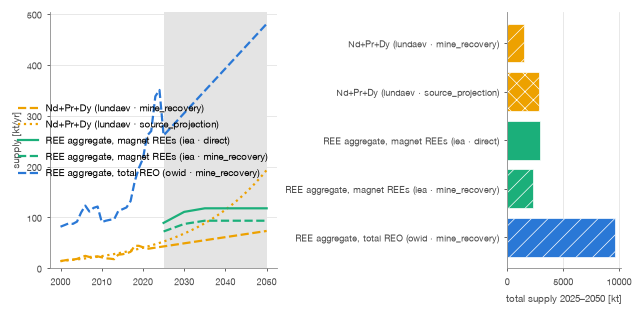

In [7]:
REE_PARTS = list(
    mineral_info.loc[
        mineral_info[MineralInfo.group] == MineralGroup.magnet_rees, MineralInfo.mineral
    ]
)

# Build the series once so the yearly lines and the window-total bars stay in
# sync. Each entry: (label, colour, line style, bar hatch, yearly series, total).
entries = []
for method in ("mine_recovery", "source_projection"):
    sel = {"source": "lundaev", "mineral": REE_PARTS, "method": method}
    yearly = supply["supply"].sel(sel).sum("mineral", min_count=len(REE_PARTS)).to_pandas()
    total = supply["total_supply"].sel(sel).sum("mineral", min_count=len(REE_PARTS)).item()
    entries.append((
        f"Nd+Pr+Dy (lundaev · {method})", SOURCE_COLORS["lundaev"],
        METHOD_STYLES[method], METHOD_HATCHES[method], yearly, total,
    ))

for source, method in (("iea", "direct"), ("iea", "mine_recovery"), ("owid", "mine_recovery")):
    sel = {"source": source, "mineral": "Rare earth elements", "method": method}
    yearly = supply["supply"].sel(sel).to_pandas()
    total = supply["total_supply"].sel(sel).item()
    scope = "magnet REEs" if source == "iea" else "total REO"
    entries.append((
        f"REE aggregate, {scope} ({source} · {method})", SOURCE_COLORS[source],
        METHOD_STYLES[method], METHOD_HATCHES[method], yearly, total,
    ))

fig, (ax_yearly, ax_total) = plotting.page_figure(style, ncols=2, width_ratios=[2, 1])

for label, color, line_style, _hatch, yearly, _total in entries:
    ax_yearly.plot(yearly.index, yearly, line_style, color=color, lw=1.6, label=label)
ax_yearly.axvspan(*WINDOW, color=ink["grid"], lw=0, zorder=0)
ax_yearly.set_ylim(bottom=0)
plotting.style_panel(ax_yearly, style, title=None, ylabel="Supply [kt/yr]")
legend = ax_yearly.legend(frameon=False)

positions = range(len(entries))
bars = ax_total.barh(
    list(positions), [e[5] for e in entries], color=[e[1] for e in entries],
    edgecolor=style["bar"]["edge_color"], linewidth=style["bar"]["edge_width"],
)
for bar, entry in zip(bars, entries):
    bar.set_hatch(entry[3])
ax_total.set_yticks(list(positions), [e[0] for e in entries], color=ink["secondary"])
ax_total.invert_yaxis()
ax_total.set_xlim(left=0)
plotting.style_panel(
    ax_total, style, title=None, orientation="horizontal",
    ylabel=f"Total supply {WINDOW[0]}–{WINDOW[1]} [kt]",
)

plotting.save_figure(fig, figures_dir, "ree_sanity_check", style, (legend,))
plt.show()

## Observations

- Where a metal has several long series, the methods bracket a plausible range
  (e.g. nickel, manganese); wide spreads flag either short input series
  (copper's OWID refinery series only starts in 2020) or genuinely divergent
  outlooks (lithium: IEA base case vs pre-boom Lundaev history).
- Lundaev bell curves (`source_projection`) generally run above the linear
  extrapolations — they model logistic growth towards a resource-limited peak.
- For gallium, `host_ratio` exceeds `direct`: gallium production has grown
  faster than a straight line, and the trending ratio carries that forward.

## Chosen sources and methods

The downstream analysis needs a single supply series per metal, not the full
spread of methods above. Each choice is recorded in `data/mineral_info.csv` as
`chosen_supply_source` + `chosen_supply_method`, with `includes_secondary_supply`
flagging whether that series already contains scrap/secondary metal and a short
justification in the `(source, method) choice)` column. The picks follow one
consistent rule rather than a per-metal judgement call — so each is explainable
and, where a metal has several options, defensible against the alternatives in
the plots.

**Method priority** depends on **how the metal is produced**, because the most
defensible *projection* is not always the series that best fits history:

- **Single-host by-products** (gallium, germanium, iridium) → `host_ratio`:
  host mine series × extrapolated by-product ratio. Their future output is
  mechanistically *set by* how much host is processed, so a host-coupled
  projection is more defensible than a trend line through the by-product's own
  series — and extrapolating the ratio carries forward the recovery buildout
  (e.g. gallium). This is preferred over `direct` even where `direct` fits
  history well (germanium): `direct` is faithful to the past, `host_ratio` is
  the better *prediction*. (Caveat: the ratio is extrapolated with no upper cap,
  so sanity-check that a rising ratio doesn't run away.)
- **Primary metals, and by-products with no single host** → `direct`, else
  `mine_recovery`:
  1. `direct` — a genuine final-stage series (refinery, smelter for Al, or the
     OWID "processing" catch-all), used as-is. The market-ready output, with no
     conversion assumptions.
  2. `mine_recovery` — mine-stage series × smelting+refining recovery rate,
     when no final-stage series exists. Also the fallback for multi-host
     by-products, where host-coupling is undefined (cobalt has two hosts,
     vanadium none).
- `source_projection` — **not chosen for any metal.** The Lundaev bell curve is
  a logistic/Hubbert resource-depletion model; the authors state explicitly it
  is *"not to project the future supply, but to analyse resource management
  possibilities … estimating theoretical production trends and peaks"*
  (Lundaev et al. 2023). Kept only as an optimistic, resource-limited bound and
  for the REE sanity check above.

**Source priority** — within the chosen method:

1. `iea` — a genuine forward supply outlook (base case), where the metal is in
   the IEA Critical Minerals scope. For IEA we prefer `direct`: its refinery and
   mine blocks are modelled independently, and refined output routinely exceeds
   domestic mine output (stockpiles, scrap, imports), so `mine_recovery`
   (mine × recovery) systematically *understates* refined supply — e.g. for
   copper, IEA `direct` ≈ 1.8× IEA `mine_recovery`. This is also why
   `includes_secondary_supply` is `true` for exactly these IEA `direct` refined
   picks and `false` for the primary mine-based series.
2. `owid` — USGS/BGS observed production, linearly extrapolated. The
   authoritative history to fall back on where IEA has no projection.
3. `lundaev` history — only when OWID lacks a usable series (notably the
   individual magnet REEs, which have no standalone OWID/IEA series, and iridium,
   whose OWID rows are country-only with no World aggregate).

**Rare earths (Nd, Pr, Dy).** Only Lundaev resolves the individual magnet REEs,
so these are forced onto `lundaev`. We use `lundaev · mine_recovery` — observed
production linearly extrapolated — for transparency and consistency with every
other non-IEA metal, keeping the whole selection on one traceable basis.
`source_projection` integrates to a window total closer to the IEA magnet
aggregate (≈ Nd+Pr+Dy+Tb, with Tb only ~0.8% of the basket), but it is a
separate model the authors disclaim as a forecast; keeping `mine_recovery`
leaves that IEA agreement as an *independent* cross-check rather than a fitted
target. The Nd:Pr:Dy split (≈ 75 : 23 : 3) is identical under either method and
matches recent mine production, so this choice affects only the overall level,
not the allocation across the three.

## Confidence in each chosen supply

`data/mineral_info.csv` carries a `confidence` rating (`high` / `medium` / `low`)
for each chosen supply, propagated to `final_supply.csv`. It is a **qualitative
judgement of how much to trust the level** of the projected window total — not a
formal uncertainty — combining:

- **method directness** — `direct` (measured final-stage output, no conversion)
  is trusted most; `mine_recovery` / `host_ratio` add one modelled step; a forced
  single-source pick least;
- **input-series adequacy** — a long observed series beats a short one (OWID's
  2020–2024 platinum / copper-refinery series) or a country-only one (iridium);
- **cross-checks** — independent estimates of the *same* quantity that agree
  raise confidence; a wide spread among them, or a level other evidence
  contradicts, lowers it. The IEA `direct` ↔ `mine_recovery` gap is **not** such a
  disagreement — it is the well-understood stage / secondary-supply effect flagged
  by `includes_secondary_supply` (refined output draws on scrap and stockpiles
  beyond domestic mine), so it does **not** lower confidence;
- **scope caveats** — e.g. IEA graphite is battery-grade only; the magnet REEs are
  forced onto a single Lundaev series whose *level* is uncertain (`mine_recovery`
  sits ~2× below the IEA magnet aggregate; see the REE sanity check).

| rating | basis | metals | note |
|---|---|---|---|
| **high** | `direct` refined output from IEA/OWID, long series, a corroborating estimate | aluminium, copper, nickel | Copper is high despite a wide method spread, because the two direct estimates (IEA, OWID) agree |
| **medium** | one solid conversion (incl. a host-coupled by-product ratio), or `direct` with a scope caveat / uncertain outlook / genuine cross-source spread | cobalt, lithium, graphite, manganese, gallium, germanium, vanadium | Lithium is medium due to large disagreement between IEA and OWID projections; germanium is medium as it has a small tonnage and is a by-product; gallium is medium because host_ratio extrapolates a rising ratio with no upper cap |
| **low** | forced single-source, tiny tonnage, short series, or a level independent evidence questions | platinum, iridium, neodymium, praseodymium, dysprosium | |

This is a judgement call, not a computed quantity — adjust the ratings in
`mineral_info.csv` as the inputs, scope, or your risk tolerance change (the
`output_final_supplies` rule only enforces that every chosen metal carries one of
the three levels).